# MA22037 coursework (2025-26)

# TODOs / Notes (Delete)
- Section A by W.C 30/03
- Juypter -> Save as HMTL -> CTRL+P -> Save as PDF -> mess with margins
- GenAI statement
- Can swap infinite series and integrals
- use \align{begin*} etc later on
- add dx to integrals

# Gen-AI Statement

I used Generative AI for the following things within this notebook:
- Finding previously unused LaTeX symbols such as $ \left[...\right]_0^1 $ and piecewise function definition in LaTeX (A2)
- 

# Section A

## A1

**a)**
<br><br> Using the Fourier expression of $ u(x) $,


$$
\int_0^1 |u(x)|^2 \ dx = \int_0^1 | \sum_{k=-\infty}^{\infty} u_k e^{2k \pi i x} | ^2
$$

By using $ \sum_{k=-\infty}^\infty | f(x) | ^2 = \sum_{k=-\infty}^\infty \sum_{j=-\infty}^\infty f_k(x) \overline{(f_j(x))} $,

$$
\begin{align*}
\int_0^1 |u(x)|^2 \ dx &= \int_0^1 \sum_{k=-\infty}^\infty \sum_{j=-\infty}^\infty u_k \bar{u_j} e^{2 \pi i x (k-j)} \ dx \\
& = \sum_{k,j=-\infty}^\infty \int_0^1 u_k \bar{u_j} e^{2 \pi i x (k-j)} \ dx \\
& = \sum_{k,j=-\infty}^\infty u_k \bar{u_j} \int_0^1  e^{2 \pi i x (k-j)} \ dx \hspace{10mm} (1)
\end{align*}
$$

Now, we prove that the integral in $ \mathbb{(1)} $ follows the Kronecker delta $ \delta_{j,k} $

$$
\begin{align*}
\int_0^1  e^{2 \pi i x (k-j)} \ dx & = \left[ \frac{e^{2\pi i (k-j)x}}{2\pi i (k-j)} \right]_{0}^{1} \\
& = \frac{1}{2\pi i (k-j)}\left[e^{2 \pi i (k-j)} - 1  \right]
\end{align*}
$$

Since $ (k-j) \in \mathbb{Z}, \ \ e^{2(k-j) \pi i} = 1 $ , and thus $ \mathbb{(1)} = 0 $ for $ k \neq j $.
<br> For $ k = j, \mathbb{(1)} $ becomes $ \int_0^1e^0 \ dx = \int_0^11 \ dx = 1 $
<br>
<br> Back to the original proof now, the double sum simplifies as follows:

$$
\begin{align*}
\int_0^1 |u(x)|^2 \ dx & = \sum_{k,j = - \infty}^{\infty} u_k \bar{u_j} \delta_{k,j} \\
& = \sum_{k = - \infty}^{\infty} u_k \bar{u_k} \\
& = \sum_{k = - \infty}^{\infty} | u_k |^2 \hspace{3mm} \square
\end{align*}
$$

<br><br> **b)**

Using Hint 2, 

$$
\begin{align*}
u(x) \times e^{-2k \pi i x} & = \sum_{j=- \infty}^{\infty} u_j e^{2j \pi i x} \times e^{-2k \pi i x} \\
& = \sum_{j=- \infty}^{\infty} u_j e^{2(j-k) \pi i x}
\end{align*}
$$

Now, integrating over [0,1],

$$
\begin{align*}
\int_0^1 \sum_{j=- \infty}^{\infty} u_j e^{2(j-k) \pi i x} & = \sum_{j=- \infty}^{\infty} u_j \int_0^1 e^{2(j-k) \pi i x} \\
& = \sum_{j=- \infty}^{\infty} u_j \delta_{j,k} \hspace{5mm} \ from \ \mathbb{(1)} \\
& = u_k \hspace{3mm} \square
\end{align*}
$$



## A2

We can use the result from A1 part b) to directly compute the Fourier coefficients for u(x)

$$
\begin{align*}
u_k 
& = \int_0^1u(x) \times e^{-2 \pi k i x} \\
& = \int_0^{1/2} 0 \times e^{-2 \pi k i x} + \int_{1/2}^1 1 \times e^{-2 \pi k i x} \\
& = \int_{1/2}^1 e^{-2 \pi k i x} \\
& = \frac{\left[ e^{-2 \pi i k x} \right]_{1/2}^1}{-2 \pi i k} \\ \\
& = \frac{\left[ e^{-2 \pi i k} - e^{- \pi i k} \right]}{- 2 \pi i k} \\
\end{align*}
$$
However, $e^{-2 \pi k i} = 1$ and $ e^{- \pi k i} = (-1)^k $
<br> $u_k$ thus simplifies to:

$$
\begin{align*}
u_k 
& = \frac{1 -(-1)^k}{- 2 \pi i k} \\ \\
& = \frac{(-1)^k - 1}{2 \pi i k}
\end{align*}
$$

Considering the case k = 0, we observe

$$
\begin{align*}
u_0 = \int_0^1 u(x)e^0 = \frac{1}{2}
\end{align*}
$$

Finally,

$$
\
u_k =
\begin{cases}
\text{ $\frac{1}{2}$ }, & \text{k=0} \\
\text{0}, & \text{k \ even} \\
\text{$\frac{i}{\pi k}$}, & \text{k \ odd}
\end{cases}
\
$$






## A3

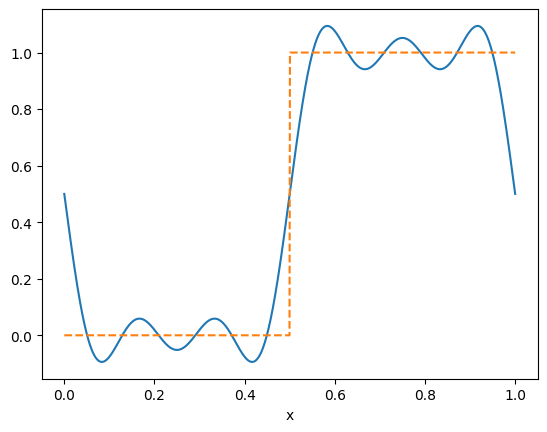

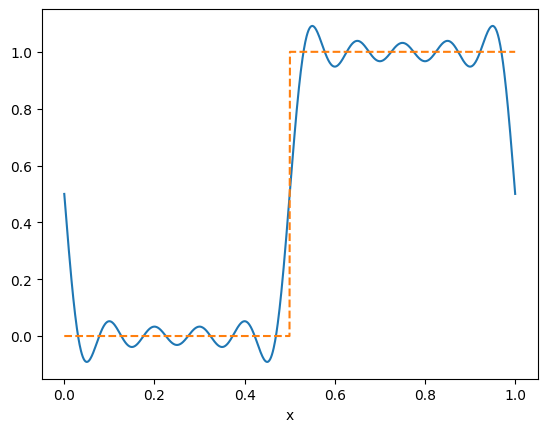

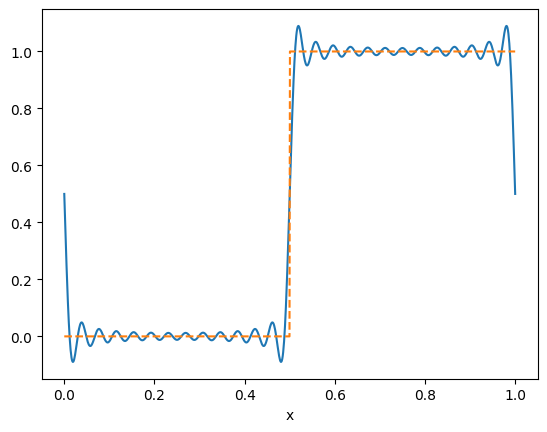

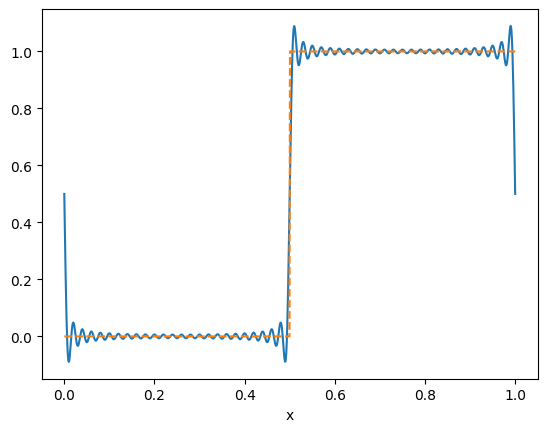

In [ ]:
import numpy as np

def eval_uj(J, x):
	uJ_x = 0
	for k in range(-J, J + 1):
		u_k = 0
		if k == 0:
			u_k = 1/2
		elif k % 2 == 0:
			u_k = 0
		else:
			u_k = 1j / (np.pi * k)
		uJ_x += (u_k * np.exp(2 * np.pi * 1j * k * x))
	return uJ_x

def step_fn(J):
	N=1000
	grid=np.linspace(0,1,N)
	uJ = []
	for point in grid:
		uJ.append(eval_uj(J, point).real)
	return grid, uJ

import matplotlib.pyplot as plt

step = [0 if x < 1/2 else 1 for x in np.linspace(0,1,1000)]

J = [5,10,25,50]
for j in J:
	x, y = step_fn(j)
	plt.plot(x, y)
	plt.legend()
	plt.plot(x, step, linestyle="dashed")
	plt.show()




Main features of approximation
* The approximation gets more accurate the further away it is from discontinuous points / end points.
* The approximation is worst at the end points, with massive errors occuring as x $\rightarrow$ 1 and x $\leftarrow$ 0.
* As J increases, the peaks and trophs of the sin/cos oscillations get smaller in magnitude, thus approximating the line better.

## A4

## A5

# Section B

## B1

In [2]:
def per_trap(u,J):
    #FILL IN
    return I


## B2

## B3


# Section C

## C1

In [3]:
def compress(A, J):
    # assume img is black-and-white or a slice A(:,:,i) of a rgb image
    Ahat = fft2(A)
    
    #FILL IN
    #Chat = #keep only most important  4J^2 coefficients in Ahat
    
    C = np.real(ifft2(Chat)) #only interested in real part
    return C


## C2

In [4]:
#inputs: image im
#        J = coefficients in each block
#        D = size of blocks
def compress_v2(im, J, D):
    # FILL IN
    return C, total_coefficients
